# Análisis exploratorio de los datos (EDA)

Proyecto final, Simulación y Aprendizaje por Refuerzo — Agente inversor.

Este cuaderno describe la serie de GOOGL usada por el agente y justifica, con evidencia, las
decisiones de estado y recompensa. Se ejecuta desde la raíz del repositorio:

```bash
uv run --with jupyter jupyter nbconvert --to notebook --execute --inplace notebooks/eda.ipynb
```

**Regla de este cuaderno.** Las estadísticas descriptivas se muestran para cada tramo, pero
toda conclusión que se usa para diseñar el estado o la recompensa (sección 6) se calcula
**solo con el tramo de entrenamiento**. Mirar validación o prueba para elegir indicadores
sería una fuga de información del futuro.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from gym_anytrading.datasets import STOCKS_GOOGL

from agente_inversor import datos, envs

RES = Path("resultados")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
VENTANA = 20

## 1. Datos y partición cronológica

Velas diarias de GOOGL (Open, High, Low, Close, Volume) del conjunto que trae `gym-anytrading`.
El agente solo usa el cierre; el volumen se analiza para justificar por qué no se incluyó.

In [2]:
velas = STOCKS_GOOGL.copy()
velas.index = pd.to_datetime(velas.index)
serie = datos.cargar()
tramos = datos.particion(len(serie), VENTANA)
print(velas.shape, velas.index.min().date(), "a", velas.index.max().date())
print("Valores faltantes:", int(velas.isna().sum().sum()))
print("Close == Adj Close en todos los días:", bool(np.allclose(velas["Close"], velas["Adj Close"])))

ret = np.log(serie).diff().dropna()
filas = []
for t in tramos.values():
    r = ret.iloc[t.inicio : t.fin - 1]   # retornos cobrados en el tramo
    p = serie.iloc[t.inicio : t.fin]
    filas.append({
        "tramo": t.nombre, "desde": p.index[1].date(), "hasta": p.index[-1].date(), "días": len(r),
        "retorno total %": (p.iloc[-1] / p.iloc[0] - 1) * 100,
        "media diaria %": r.mean() * 100, "vol. anual %": r.std() * np.sqrt(252) * 100,
        "asimetría": stats.skew(r), "curtosis exceso": stats.kurtosis(r),
        "% días al alza": (r > 0).mean() * 100,
    })
desc = pd.DataFrame(filas).set_index("tramo")
desc.round(2)

(2335, 6) 2009-05-22 a 2018-08-29
Valores faltantes: 0
Close == Adj Close en todos los días: True


,desde,hasta,días,retorno total %,media diaria %,vol. anual %,asimetría,curtosis exceso,% días al alza
tramo,,,,,,,,,
entrenamiento,2009-06-23,2015-11-16,1613,268.07,0.08,25.06,0.86,13.43,52.32
validacion,2015-11-17,2017-04-07,350,12.22,0.03,18.87,-0.55,2.53,51.71
prueba,2017-04-10,2018-08-29,351,50.18,0.12,21.42,-0.72,2.52,54.70


Los tres tramos tienen comportamientos muy distintos: entrenamiento es un mercado alcista largo,
validación es casi lateral y prueba vuelve a ser alcista. Esto anticipa el problema de
**no estacionariedad** que discute el informe.

## 2. Evolución del precio y caídas (drawdown)

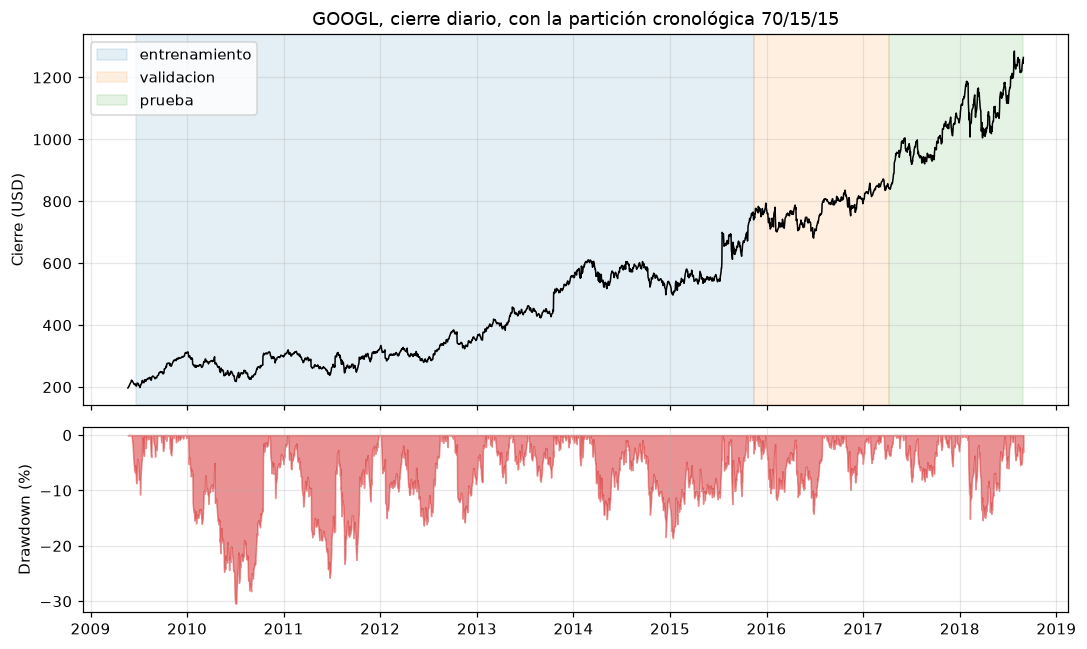

Máximo drawdown de la serie completa: -30.4 % (2010-07-06)
  entrenamiento  máx. caída dentro del tramo:  -30.4 %
  validacion     máx. caída dentro del tramo:  -14.2 %
  prueba         máx. caída dentro del tramo:  -15.4 %


In [3]:
dd = serie / serie.cummax() - 1
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(serie, color="black", lw=1)
colores = {"entrenamiento": "tab:blue", "validacion": "tab:orange", "prueba": "tab:green"}
for t in tramos.values():
    ax[0].axvspan(serie.index[t.inicio], serie.index[t.fin - 1], alpha=0.12, color=colores[t.nombre], label=t.nombre)
ax[0].set_ylabel("Cierre (USD)"); ax[0].legend(loc="upper left")
ax[0].set_title("GOOGL, cierre diario, con la partición cronológica 70/15/15")
ax[1].fill_between(dd.index, dd * 100, color="tab:red", alpha=0.5)
ax[1].set_ylabel("Drawdown (%)")
fig.tight_layout(); fig.savefig(RES / "eda_precio_drawdown.png", dpi=150); plt.show()

print("Máximo drawdown de la serie completa: %.1f %% (%s)" % (dd.min() * 100, dd.idxmin().date()))
for t in tramos.values():
    p = serie.iloc[t.inicio : t.fin]
    print(f"  {t.nombre:<14} máx. caída dentro del tramo: {((p / p.cummax()) - 1).min() * 100:6.1f} %")

El precio pasa de unos 200 a más de 1.200 USD. La caída más profunda de la serie (−30,4 %,
con fondo en julio de 2010) está dentro de entrenamiento; validación y prueba solo tienen
caídas máximas de 14-15 %. El agente aprende en un régimen con más subidas que bajadas y casi sin caídas
largas, lo que explica por qué tiende a parecerse a comprar y mantener.

## 3. Distribución de los retornos diarios

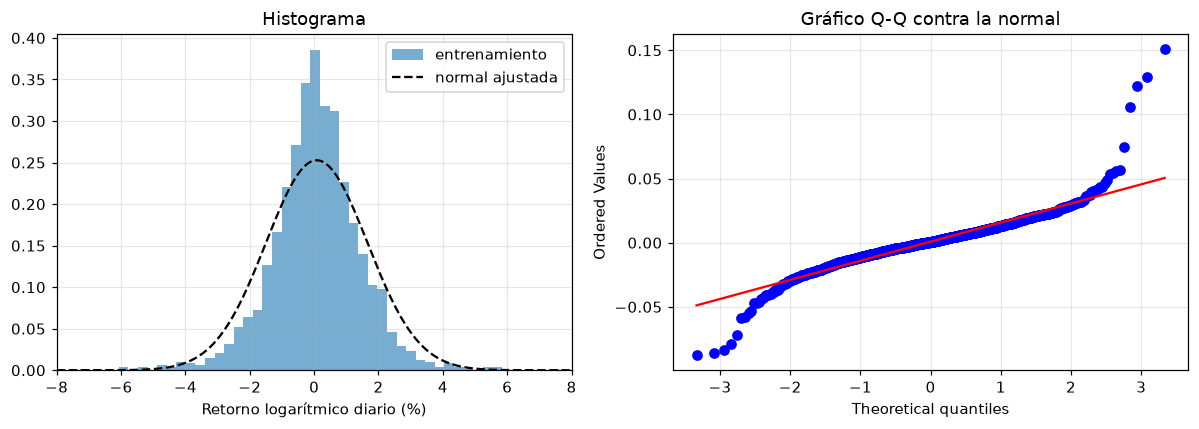

Jarque-Bera (entrenamiento): estadístico 12320, p = 0.00e+00
Días con |retorno| > 4 sigmas: 10 (la normal esperaría 0.10)


In [4]:
r_ent = ret.iloc[tramos["entrenamiento"].inicio : tramos["entrenamiento"].fin - 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(r_ent * 100, bins=80, density=True, alpha=0.6, label="entrenamiento")
x = np.linspace(-8, 8, 400)
ax[0].plot(x, stats.norm.pdf(x, r_ent.mean() * 100, r_ent.std() * 100), "k--", label="normal ajustada")
ax[0].set_xlim(-8, 8); ax[0].set_xlabel("Retorno logarítmico diario (%)"); ax[0].legend()
ax[0].set_title("Histograma")
stats.probplot(r_ent, dist="norm", plot=ax[1]); ax[1].set_title("Gráfico Q-Q contra la normal")
fig.tight_layout(); fig.savefig(RES / "eda_retornos.png", dpi=150); plt.show()

jb = stats.jarque_bera(r_ent)
print(f"Jarque-Bera (entrenamiento): estadístico {jb.statistic:.0f}, p = {jb.pvalue:.2e}")
print(f"Días con |retorno| > 4 sigmas: {(np.abs(r_ent - r_ent.mean()) > 4 * r_ent.std()).sum()}"
      f" (la normal esperaría {len(r_ent) * 2 * stats.norm.sf(4):.2f})")

Los retornos tienen colas mucho más pesadas que una normal (curtosis en exceso alta, Jarque-Bera
rechaza normalidad). Consecuencias para el diseño:

* unos pocos días extremos (p. ej. resultados trimestrales) pesan mucho en la recompensa; una
  recompensa sin escala daría gradientes muy desiguales, por eso la recompensa se expresa en
  puntos porcentuales y se usa el **retorno logarítmico**, aditivo en el tiempo;
* normalizar los indicadores con media y desviación globales sería frágil ante esos extremos, y
  además miraría el futuro; por eso cada indicador se escala con la **volatilidad de su propia ventana**.

## 4. Volatilidad: periodos de calma y de estrés

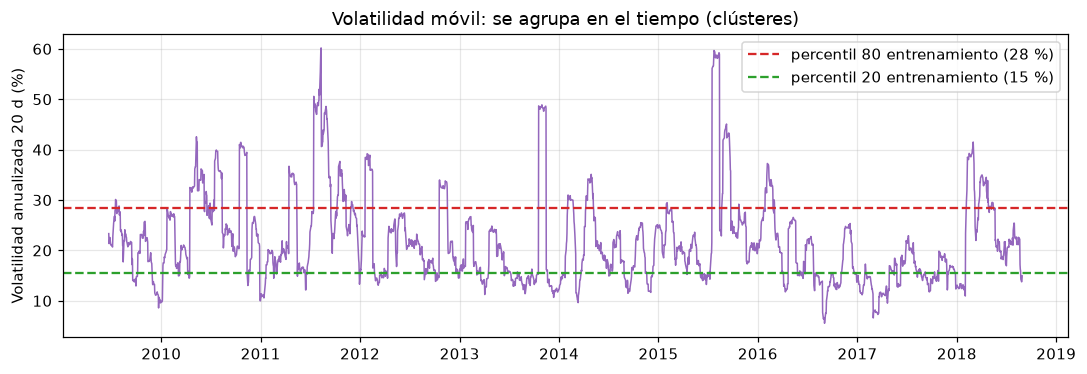

,1,2,3,4,5,6,7,8,9,10
autocorr. retorno,0.028,0.010,-0.019,0.001,-0.018,0.004,-0.029,-0.011,0.007,0.026
autocorr. |retorno|,0.061,0.047,0.064,0.092,0.045,0.030,0.034,0.075,0.024,0.013


In [5]:
vol20 = ret.rolling(VENTANA).std() * np.sqrt(252) * 100
umbral_alto, umbral_bajo = vol20.iloc[: tramos["entrenamiento"].fin].quantile([0.8, 0.2])
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(vol20, color="tab:purple", lw=1)
ax.axhline(umbral_alto, ls="--", color="tab:red", label=f"percentil 80 entrenamiento ({umbral_alto:.0f} %)")
ax.axhline(umbral_bajo, ls="--", color="tab:green", label=f"percentil 20 entrenamiento ({umbral_bajo:.0f} %)")
ax.set_ylabel("Volatilidad anualizada 20 d (%)"); ax.legend()
ax.set_title("Volatilidad móvil: se agrupa en el tiempo (clústeres)")
fig.tight_layout(); fig.savefig(RES / "eda_volatilidad.png", dpi=150); plt.show()

ac_r = [r_ent.autocorr(k) for k in range(1, 11)]
ac_abs = [r_ent.abs().autocorr(k) for k in range(1, 11)]
pd.DataFrame({"autocorr. retorno": ac_r, "autocorr. |retorno|": ac_abs}, index=range(1, 11)).round(3).T

La autocorrelación de los retornos es prácticamente cero (el precio de mañana es casi
impredecible a partir del de hoy), pero la autocorrelación de su **valor absoluto** es pequeña y sistemáticamente
positiva en los diez rezagos: la volatilidad se agrupa. Esto justifica incluir la **volatilidad reciente** en el
estado: aunque no anticipe la dirección, sí anticipa el tamaño del riesgo del día siguiente, que
es lo que debería pesar al decidir cuánto capital exponer.

## 5. Volumen

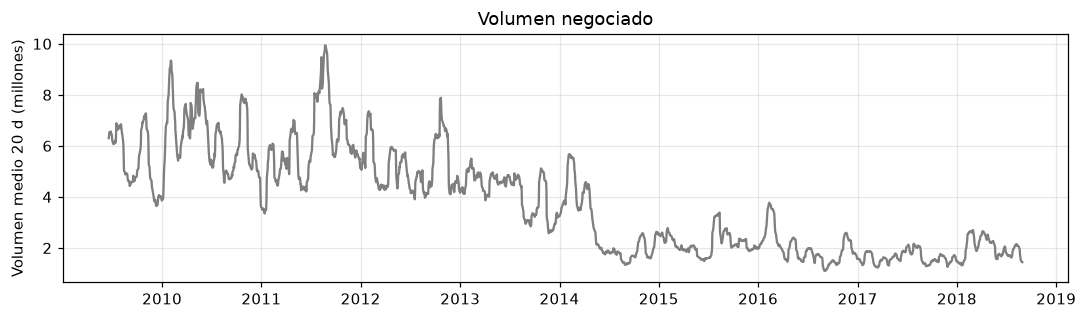

Corr. cambio de volumen vs |retorno| del mismo día: 0.373
Corr. cambio de volumen vs retorno del día siguiente: 0.02


In [6]:
vol_n = velas["Volume"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(vol_n.rolling(20).mean() / 1e6, color="tab:gray")
ax.set_ylabel("Volumen medio 20 d (millones)")
ax.set_title("Volumen negociado")
fig.tight_layout(); fig.savefig(RES / "eda_volumen.png", dpi=150); plt.show()

ent = slice(tramos["entrenamiento"].inicio, tramos["entrenamiento"].fin - 1)
cambio_vol = np.log(vol_n).diff()
siguiente = ret.shift(-1)
df_v = pd.DataFrame({"cambio_vol": cambio_vol, "abs_ret": ret.abs(), "ret_sig": siguiente}).iloc[ent].dropna()
print("Corr. cambio de volumen vs |retorno| del mismo día:", round(df_v["cambio_vol"].corr(df_v["abs_ret"]), 3))
print("Corr. cambio de volumen vs retorno del día siguiente:", round(df_v["cambio_vol"].corr(df_v["ret_sig"]), 3))

El volumen medio diario cae de forma sostenida, de unos 6 millones de acciones en 2010-2011 a
cerca de 2 millones en 2016-2018, así que no es estacionario. Se mueve con el tamaño del retorno del
mismo día, pero no aporta información sobre la dirección del día siguiente. Se decidió **no
incluirlo en el estado**: añadiría una variable con cambio de régimen y sin señal direccional.

## 6. Comportamiento de los indicadores del estado (solo entrenamiento)

Se recorren todos los días del tramo de entrenamiento con el mismo entorno que usa el agente y se
registran los seis indicadores de precio. Así se analiza exactamente lo que ve el agente.

In [7]:
t = tramos["entrenamiento"]
env = envs.EntornoInversion(serie.to_numpy(), t.inicio, t.fin, ventana=VENTANA)
env.reset(seed=0)
obs = []
for dia in range(t.inicio, t.fin - 1):
    env.t = dia
    obs.append(env._obs()[:6])
nombres = ["ultimo_ret", "momento_5", "momento_20", "cruce_medias", "vol_anual", "dist_maximo"]
ind = pd.DataFrame(obs, columns=nombres, index=serie.index[t.inicio : t.fin - 1])
ind["ret_siguiente_%"] = ret.shift(-1).loc[ind.index] * 100
ind.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ultimo_ret,1613.0,0.056,1.046,-4.032,-0.517,0.039,0.656,4.372
momento_5,1613.0,0.129,1.084,-3.632,-0.606,0.145,0.814,3.361
momento_20,1613.0,0.289,1.036,-2.414,-0.510,0.274,1.120,3.026
cruce_medias,1613.0,0.107,0.448,-1.019,-0.223,0.129,0.418,1.282
vol_anual,1613.0,0.226,0.093,0.084,0.159,0.205,0.261,0.587
dist_maximo,1613.0,-0.525,0.497,-2.256,-0.864,-0.417,-0.066,0.000
ret_siguiente_%,1613.0,0.081,1.579,-8.749,-0.682,0.058,0.854,15.065


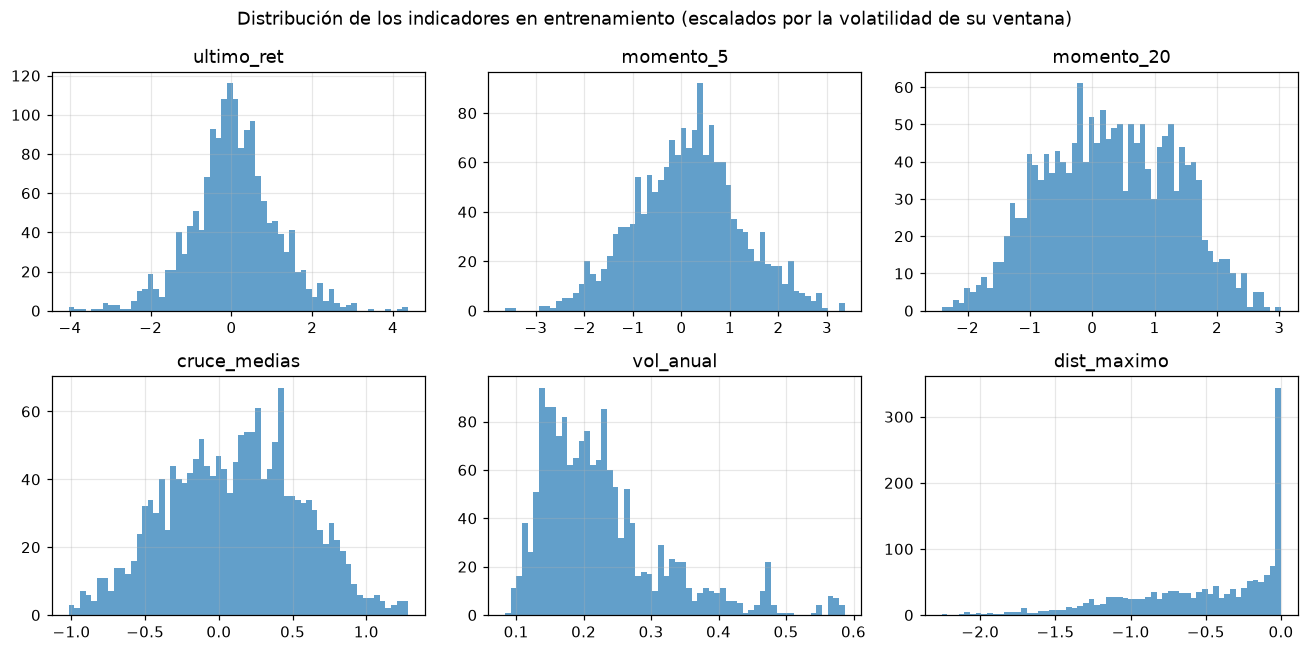

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axs.flat, nombres):
    ax.hist(ind[c], bins=60, color="tab:blue", alpha=0.7)
    ax.set_title(c)
fig.suptitle("Distribución de los indicadores en entrenamiento (escalados por la volatilidad de su ventana)")
fig.tight_layout(); fig.savefig(RES / "eda_indicadores.png", dpi=150); plt.show()

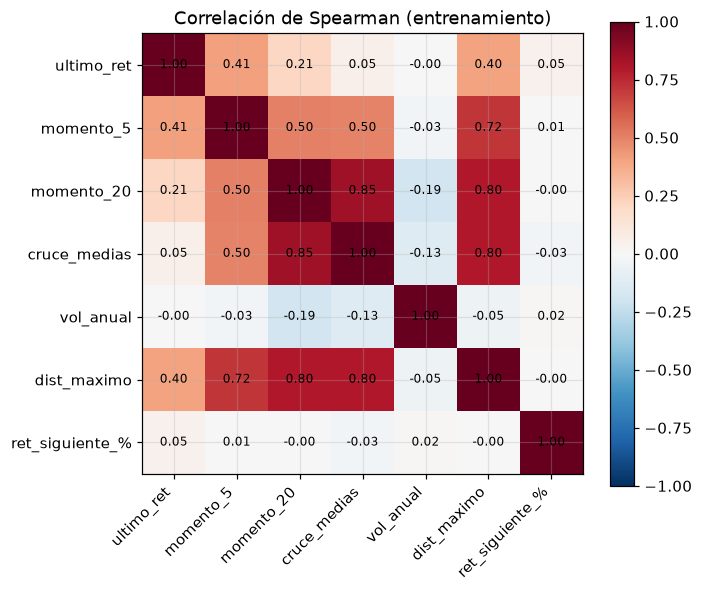

,corr. con retorno siguiente,umbral 95 % (±2/√n)
ultimo_ret,0.047,0.05
momento_5,0.007,0.05
momento_20,-0.002,0.05
cruce_medias,-0.031,0.05
vol_anual,0.015,0.05
dist_maximo,-0.002,0.05


In [9]:
corr = ind.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Correlación de Spearman (entrenamiento)")
fig.tight_layout(); fig.savefig(RES / "eda_correlaciones.png", dpi=150); plt.show()

ic = corr["ret_siguiente_%"].drop("ret_siguiente_%")
n = len(ind)
pd.DataFrame({"corr. con retorno siguiente": ic, "umbral 95 % (±2/√n)": 2 / np.sqrt(n)}).round(3)

**Lectura.**

* Las escalas quedan comparables (casi todos los indicadores entre -3 y 3) sin usar ninguna
  estadística global de la serie: es la razón de dividir por la volatilidad de la ventana.
* Momento a 20 días, cruce de medias y distancia al máximo están muy correlacionados entre sí
  (Spearman 0,80 a 0,85): miden variantes de la tendencia. La volatilidad, en cambio, es casi
  independiente de los demás, así que aporta información distinta. Se conservaron porque una red neuronal tolera la redundancia
  y cada uno reacciona a distinta velocidad, pero es una simplificación posible.
* La correlación de cada indicador con el retorno del día siguiente es muy pequeña (del orden de
  ±0,05), cerca del umbral de ruido. **La señal predictiva disponible en el precio es débil**, lo que
  pone una expectativa realista: no es razonable esperar que el agente supere con holgura a comprar
  y mantener. Este resultado del EDA anticipa el resultado principal del proyecto.

## 7. Auditoría de información del futuro (lookahead)

Comprobación empírica, además de la prueba unitaria del repositorio: si se alteran todos los
precios **posteriores** a un día *t*, el estado en *t* no debe cambiar.

In [10]:
p = serie.to_numpy()
rng = np.random.default_rng(0)
dias = rng.integers(t.inicio, t.fin - 1, size=200)
violaciones = 0
for d in dias:
    q = p.copy(); q[d + 1 :] *= rng.uniform(0.5, 2.0)
    a = envs.EntornoInversion(p, t.inicio, t.fin); a.reset(seed=0); a.t = int(d)
    b = envs.EntornoInversion(q, t.inicio, t.fin); b.reset(seed=0); b.t = int(d)
    violaciones += not np.array_equal(a._obs(), b._obs())
print(f"Días auditados: {len(dias)}; estados que cambiaron al alterar el futuro: {violaciones}")

Días auditados: 200; estados que cambiaron al alterar el futuro: 0


Ningún estado cambia: los indicadores solo usan los precios de los últimos 20 días hasta *t*
inclusive. Tampoco hay escaladores ajustados sobre la serie (no hay `StandardScaler` ni
normalización global), de modo que no existe ningún parámetro que se calcule con datos de
validación o prueba.

## 8. Conclusiones del EDA que se llevan al diseño

1. **Estado**: tendencia (momento 5 y 20 días, cruce de medias), riesgo (volatilidad, distancia al
   máximo), último retorno y la exposición actual; todos escalados localmente.
2. **Volumen excluido**: no estacionario y sin señal direccional.
3. **Recompensa** en retorno logarítmico y en puntos porcentuales por las colas pesadas.
4. **Expectativa**: señal predictiva débil y un entrenamiento dominado por un mercado alcista;
   comprar y mantener será un baseline difícil, y la recompensa `diferencial` (exceso sobre el
   activo) se diseñó precisamente para que el agente solo se aparte de él cuando tenga motivo.